# Étape 5 — Visualisation et interprétation

**Objectif :** rassembler les graphiques clés des étapes précédentes, ajouter 3 visualisations utiles aux recommandations
(état du parc, évolution dans le temps, comparaison des sites), et poser les **interprétations finales**.

Chaque graphique est enregistré en image dans `rapport/figures/` pour le rapport Word et le PowerPoint.

| N° | Fichier | Contenu |
|---|---|---|
| 1 | `fig01_gaz_avant_apres_log.png` | Distribution des gaz avant / après prétraitement |
| 2 | `fig02_acp_cercle_correlations.png` | Cercle des corrélations de l'ACP |
| 3 | `fig03_kmeans_groupes.png` | Groupes K-Means sur le plan de l'ACP |
| 4 | `fig04_dbscan_points_isoles.png` | Prélèvements atypiques détectés par DBSCAN |
| 5 | `fig05_importance_gaz.png` | Importance des gaz dans la forêt aléatoire |
| 6 | `fig06_regles_vers_action.png` | Règles d'association menant à une action |
| 7 | `fig07_etat_parc_ieee.png` | **Nouveau** : état actuel du parc (condition IEEE) |
| 8 | `fig08_evolution_gaz.png` | **Nouveau** : évolution des gaz de 4 transformateurs |
| 9 | `fig09_comparaison_sites.png` | **Nouveau** : comparaison des sites |

## 1. Charger les données et refaire les calculs légers

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import RandomForestClassifier
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

dossier = Path.cwd() / "data"
figures = Path.cwd() / "rapport" / "figures"
figures.mkdir(parents=True, exist_ok=True)

def enregistrer(fig, nom):
    # Enregistre le graphique en image (300 dpi : bonne qualité pour Word et PowerPoint)
    fig.savefig(figures / nom, dpi=300, bbox_inches="tight")
    print("Enregistré : rapport/figures/" + nom)

# Table de l'étape 2 + décision de l'expert (même règle qu'aux étapes 3 et 4)
table = pd.read_csv(dossier / "processed" / "dga_transformateurs_pretraite.csv",
                    dtype={"NoÉquipement": str}, parse_dates=["DatePrélèvement"])
detail = pd.read_csv(dossier / "raw" / "AnalyseDetail.csv")
recommandations = pd.read_csv(dossier / "raw" / "Recommandation.csv")
normes = pd.read_csv(dossier / "raw" / "NormesC57104.csv").set_index("Condition")

reco_gd = recommandations[recommandations["TypeAnalyse"] == "GD"][["CodeRecommandation", "Recommandation"]]
table = table.merge(detail[["CléAnalyse", "CodeRecommandation"]], on="CléAnalyse", how="left")
table = table.merge(reco_gd, on="CodeRecommandation", how="left")
table["action"] = np.where(table["Recommandation"] == "Aucune action", 0, 1)
table.loc[table["Recommandation"].isna(), "action"] = np.nan   # décision inconnue

gaz = ["H2", "CH4", "C2H2", "C2H4", "C2H6", "CO", "CO2"]
X = table[["std_" + g for g in gaz]]
print("Prélèvements :", len(table), "| Transformateurs :", table["NoÉquipement"].nunique())

Prélèvements : 4338 | Transformateurs : 292


## 2. Récapitulatif des graphiques clés
### Figure 1 — Les gaz avant et après prétraitement (étape 2)

Enregistré : rapport/figures/fig01_gaz_avant_apres_log.png


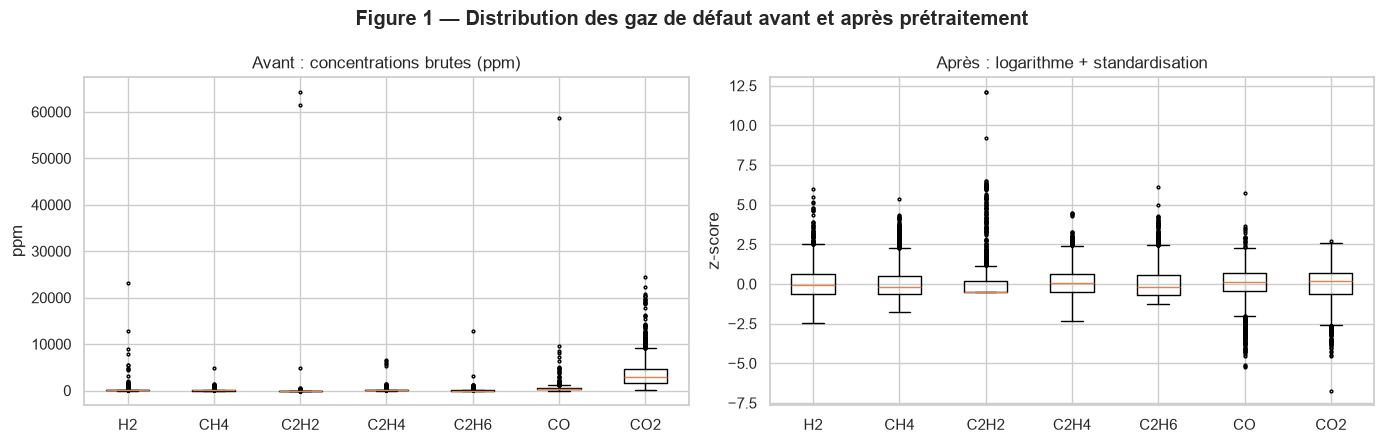

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot(table[gaz], tick_labels=gaz, flierprops={"markersize": 2})
axes[0].set(title="Avant : concentrations brutes (ppm)", ylabel="ppm")
axes[1].boxplot(X, tick_labels=gaz, flierprops={"markersize": 2})
axes[1].set(title="Après : logarithme + standardisation", ylabel="z-score")
fig.suptitle("Figure 1 — Distribution des gaz de défaut avant et après prétraitement", fontweight="bold")
plt.tight_layout()
enregistrer(fig, "fig01_gaz_avant_apres_log.png")
plt.show()

**Message :** les concentrations brutes sont écrasées par quelques valeurs énormes (les transformateurs en défaut). Après logarithme
et standardisation, les 7 gaz sont comparables, sans avoir supprimé ces valeurs extrêmes qui sont l'information la plus précieuse.

### Figure 2 — Cercle des corrélations de l'ACP (étape 2)

Enregistré : rapport/figures/fig02_acp_cercle_correlations.png


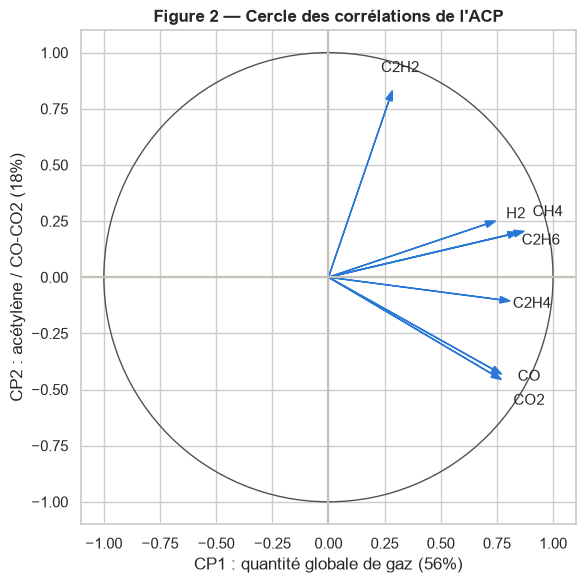

In [3]:
acp = PCA(n_components=2).fit(X)
correlations = pd.DataFrame(acp.components_.T * np.sqrt(acp.explained_variance_), index=gaz, columns=["CP1", "CP2"])
decalage = {"CH4": (0, 0.06), "C2H6": (0, -0.06), "CO": (0.03, 0.04), "CO2": (0.03, -0.04)}

fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="#52514e"))
for g in gaz:
    x, y = correlations.loc[g]
    ax.arrow(0, 0, x, y, color=COULEURS[0], head_width=0.03, length_includes_head=True)
    dx, dy = decalage.get(g, (0, 0))
    ax.text(x * 1.12 + dx, y * 1.12 + dy, g, ha="center", va="center", fontsize=11)
ax.axhline(0, color="#c3c2b7"); ax.axvline(0, color="#c3c2b7")
ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal",
       xlabel=f"CP1 : quantité globale de gaz ({acp.explained_variance_ratio_[0]:.0%})",
       ylabel=f"CP2 : acétylène / CO-CO2 ({acp.explained_variance_ratio_[1]:.0%})")
ax.set_title("Figure 2 — Cercle des corrélations de l'ACP", fontweight="bold")
plt.tight_layout()
enregistrer(fig, "fig02_acp_cercle_correlations.png")
plt.show()

**Message :** deux axes résument 74 % de l'information. CP1 mesure la **quantité globale de gaz** ; CP2 oppose l'**acétylène**
(défaut électrique, arc) au **CO/CO2** (vieillissement du papier).

### Figure 3 — Groupes K-Means (étape 3)

Enregistré : rapport/figures/fig03_kmeans_groupes.png


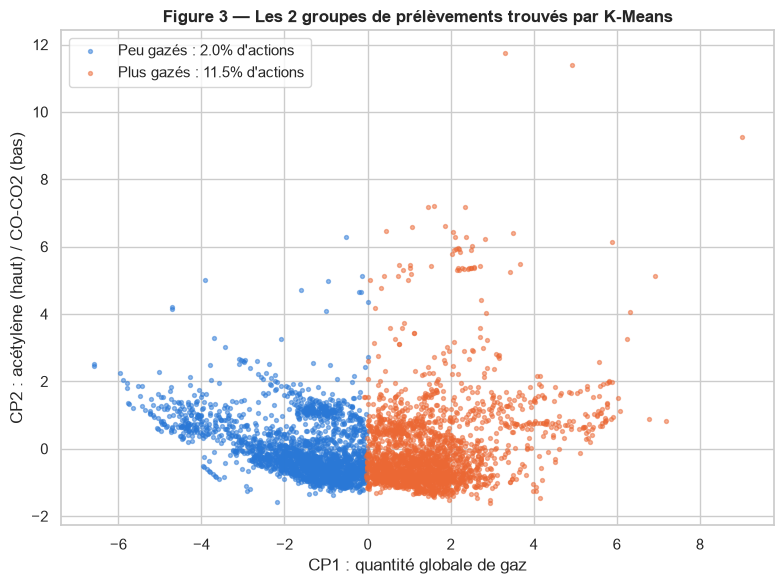

In [4]:
table["groupe"] = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
# On numérote les groupes pour que 0 = le moins gazé (la numérotation de K-Means est arbitraire)
if table.groupby("groupe")["H2"].median()[0] > table.groupby("groupe")["H2"].median()[1]:
    table["groupe"] = 1 - table["groupe"]
noms = {0: "Peu gazés", 1: "Plus gazés"}

fig, ax = plt.subplots(figsize=(8, 6))
for g in [0, 1]:
    p = table[table["groupe"] == g]
    ax.scatter(p["CP1"], p["CP2"], s=8, alpha=0.5, color=COULEURS[g],
               label=f"{noms[g]} : {p['action'].mean():.1%} d'actions")
ax.set(xlabel="CP1 : quantité globale de gaz", ylabel="CP2 : acétylène (haut) / CO-CO2 (bas)")
ax.set_title("Figure 3 — Les 2 groupes de prélèvements trouvés par K-Means", fontweight="bold")
ax.legend()
plt.tight_layout()
enregistrer(fig, "fig03_kmeans_groupes.png")
plt.show()

**Message :** sans connaître l'avis de l'expert, K-Means sépare les prélèvements **peu gazés** des **plus gazés** ;
les seconds reçoivent près de 6 fois plus souvent une recommandation d'action.

### Figure 4 — Prélèvements atypiques (DBSCAN, étape 3)

Enregistré : rapport/figures/fig04_dbscan_points_isoles.png


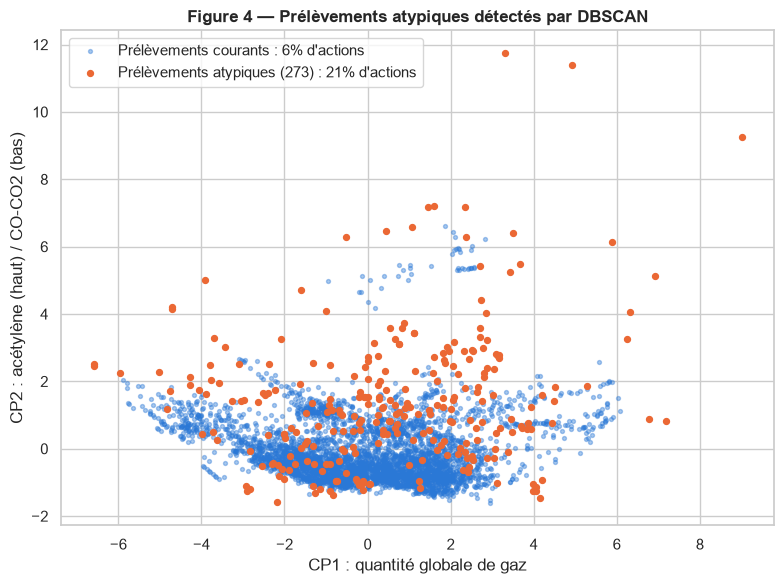

In [5]:
bruit = DBSCAN(eps=1.0, min_samples=10).fit_predict(X) == -1

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(table.loc[~bruit, "CP1"], table.loc[~bruit, "CP2"], s=8, alpha=0.4, color=COULEURS[0],
           label=f"Prélèvements courants : {table.loc[~bruit, 'action'].mean():.0%} d'actions")
ax.scatter(table.loc[bruit, "CP1"], table.loc[bruit, "CP2"], s=18, color=COULEURS[1],
           label=f"Prélèvements atypiques ({bruit.sum()}) : {table.loc[bruit, 'action'].mean():.0%} d'actions")
ax.set(xlabel="CP1 : quantité globale de gaz", ylabel="CP2 : acétylène (haut) / CO-CO2 (bas)")
ax.set_title("Figure 4 — Prélèvements atypiques détectés par DBSCAN", fontweight="bold")
ax.legend()
plt.tight_layout()
enregistrer(fig, "fig04_dbscan_points_isoles.png")
plt.show()

**Message :** DBSCAN isole 6 % de prélèvements au profil inhabituel (plus d'acétylène et d'hydrogène). L'expert les juge
**3,5 fois plus souvent** à surveiller : DBSCAN fonctionne comme un détecteur d'anomalies.

### Figure 5 — Importance des gaz (forêt aléatoire, étape 3)

Enregistré : rapport/figures/fig05_importance_gaz.png


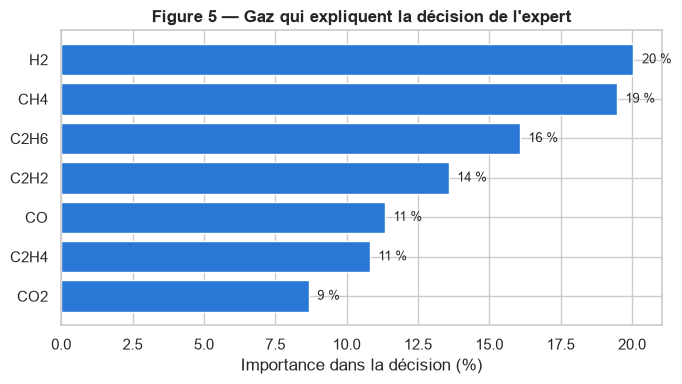

In [6]:
connus = table.dropna(subset=["action"])
foret = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1)
foret.fit(connus[["log_" + g for g in gaz]], connus["action"].astype(int))
importance = pd.Series(foret.feature_importances_ * 100, index=gaz).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color=COULEURS[0])
for y, v in enumerate(importance.values):
    ax.text(v + 0.3, y, f"{v:.0f} %", va="center", fontsize=9)
ax.set_xlabel("Importance dans la décision (%)")
ax.set_title("Figure 5 — Gaz qui expliquent la décision de l'expert", fontweight="bold")
plt.tight_layout()
enregistrer(fig, "fig05_importance_gaz.png")
plt.show()

**Message :** le modèle s'appuie d'abord sur **H2, CH4 et C2H6**, les gaz des défauts actifs (décharges, surchauffe).
CO et CO2 (vieillissement lent du papier) comptent le moins. *(Le modèle est ici réentraîné sur toutes les données :
les pourcentages peuvent légèrement différer de l'étape 3.)*

### Figure 6 — Règles d'association vers une action (étape 4)

Enregistré : rapport/figures/fig06_regles_vers_action.png


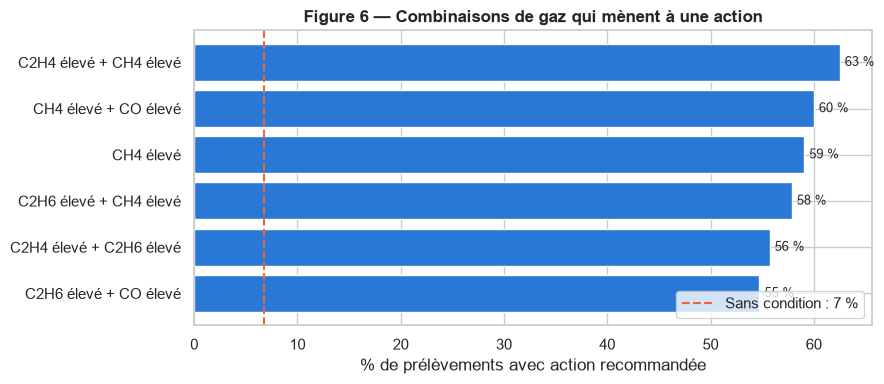

In [7]:
seuils = normes.loc[1]
paniers = pd.DataFrame({g + " élevé": connus[g] > seuils[g] for g in ["H2", "CH4", "C2H4", "C2H6", "CO", "CO2"]})
paniers["C2H2 présent"] = connus["C2H2"] >= 2
paniers["Action recommandée"] = connus["action"] == 1

regles = association_rules(apriori(paniers, min_support=0.02, use_colnames=True), metric="lift", min_threshold=1.5)
regles = regles[regles["consequents"] == frozenset({"Action recommandée"})].sort_values("confidence").tail(6)
regles["si"] = regles["antecedents"].apply(lambda x: " + ".join(sorted(x)))
base = paniers["Action recommandée"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(regles["si"], regles["confidence"] * 100, color=COULEURS[0])
ax.axvline(base, color=COULEURS[1], linestyle="--", label=f"Sans condition : {base:.0f} %")
for y, v in enumerate(regles["confidence"] * 100):
    ax.text(v + 0.5, y, f"{v:.0f} %", va="center", fontsize=9)
ax.set_xlabel("% de prélèvements avec action recommandée")
ax.set_title("Figure 6 — Combinaisons de gaz qui mènent à une action", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
enregistrer(fig, "fig06_regles_vers_action.png")
plt.show()

**Message :** quand CH4 et C2H4 sont élevés ensemble (**surchauffe de l'huile**), l'expert recommande une action dans
**62 %** des cas, contre 7 % en moyenne.

## 3. Nouvelles visualisations
### Figure 7 — État actuel du parc
Pour chaque transformateur, on prend son **dernier prélèvement** et on calcule sa **condition IEEE C57.104** à partir du
**TDCG** (*Total Dissolved Combustible Gas* = H2 + CH4 + C2H2 + C2H4 + C2H6 + CO), avec les seuils de la table `NormesC57104` :

| Condition | TDCG (ppm) | Signification |
|---|---|---|
| 1 | ≤ 720 | fonctionnement normal |
| 2 | 721 – 1 920 | gaz supérieurs à la normale : surveiller |
| 3 | 1 921 – 4 630 | niveau élevé : forte suspicion de défaut |
| 4 | > 4 630 | niveau excessif : risque de défaillance |

Enregistré : rapport/figures/fig07_etat_parc_ieee.png


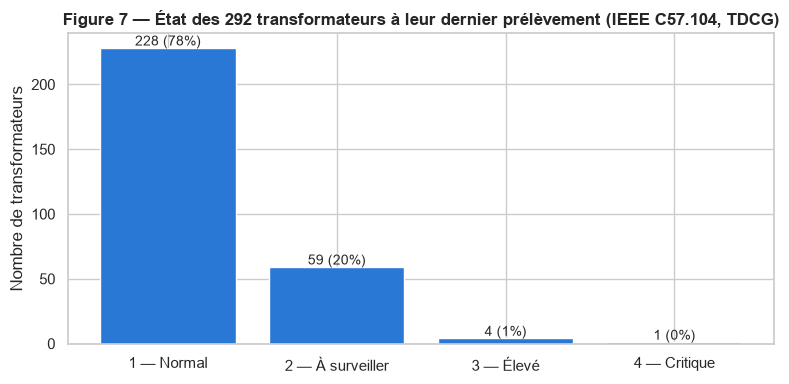

,NoÉquipement,Site,DatePrélèvement,TDCG,condition,H2,CH4,C2H2,C2H4,C2H6,CO,CO2
4294,T0218C,CCP,2009-04-29,6768.2,4,4.5,233.0,124.0,5269.0,1135.0,2.7,476.0
2057,T2003,CIM,2009-05-14,2319.0,3,10.0,99.0,0.0,320.0,117.0,1773.0,15989.0
2046,T2005,CIM,2009-05-14,2260.0,3,10.0,42.0,0.0,23.0,13.0,2172.0,7758.0
2050,T0404,CIM,2009-05-14,2082.0,3,6.0,33.0,0.0,42.0,13.0,1988.0,7228.0
2059,T2006,CIM,2009-05-14,2035.0,3,14.0,46.0,0.0,61.0,25.0,1889.0,15388.0


In [8]:
table["TDCG"] = table[["H2", "CH4", "C2H2", "C2H4", "C2H6", "CO"]].sum(axis=1)
bornes = [-np.inf, normes.loc[1, "TDCG"], normes.loc[2, "TDCG"], normes.loc[3, "TDCG"], np.inf]
table["condition"] = pd.cut(table["TDCG"], bins=bornes, labels=[1, 2, 3, 4]).astype(int)

# Dernier prélèvement de chaque transformateur
derniers = table.sort_values("DatePrélèvement").groupby("NoÉquipement").tail(1)
etat = derniers["condition"].value_counts().reindex([1, 2, 3, 4], fill_value=0)
libelles = ["1 — Normal", "2 — À surveiller", "3 — Élevé", "4 — Critique"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(libelles, etat.values, color=COULEURS[0])
for x, v in enumerate(etat.values):
    ax.text(x, v + 2, f"{v} ({v / len(derniers):.0%})", ha="center", fontsize=10)
ax.set_ylabel("Nombre de transformateurs")
ax.set_title(f"Figure 7 — État des {len(derniers)} transformateurs à leur dernier prélèvement (IEEE C57.104, TDCG)",
             fontweight="bold")
plt.tight_layout()
enregistrer(fig, "fig07_etat_parc_ieee.png")
plt.show()

# Liste des transformateurs en condition 3 ou 4 : ce sont eux que viseront les recommandations
a_surveiller = derniers[derniers["condition"] >= 3][["NoÉquipement", "Site", "DatePrélèvement", "TDCG", "condition"] + gaz]
a_surveiller.sort_values("TDCG", ascending=False)

**Interprétation :** 
- À leur dernier prélèvement, **228 transformateurs sur 292 (78 %) sont en condition 1** (normal) et **59 (20 %) en condition 2** (à surveiller).
- **5 transformateurs** dépassent la condition 2 :
  - **T0218C (site CCP) est en condition 4 (critique)** : TDCG de 6 768 ppm, avec énormément d'éthylène (5 269 ppm), d'éthane (1 135 ppm) et de l'acétylène (124 ppm). C'est la signature d'une **surchauffe sévère de l'huile, accompagnée d'un arc électrique**.
  - **4 transformateurs du site CIM sont en condition 3** (T2003, T2005, T0404, T2006). Leur TDCG est tiré par le **CO** (environ 1 800 à 2 200 ppm) et le CO2 : c'est un **vieillissement avancé du papier isolant**, pas un défaut électrique.
- **Attention :** « dernier prélèvement » ne veut pas dire « récent ». 104 transformateurs ont été mesurés en 2008-2009, mais environ 140 n'ont plus été analysés depuis l'an 2000. Leur état actuel est donc inconnu.

### Figure 8 — Évolution des gaz dans le temps
Les modèles des étapes 3 et 4 regardent chaque prélèvement **isolément**. Or l'expert regarde aussi la **tendance**.
On trace l'historique des 4 transformateurs qui ont reçu le plus de recommandations d'action.
L'axe vertical est **logarithmique** (1, 10, 100, 1 000 ppm) pour voir à la fois les petites et les grandes valeurs.

Enregistré : rapport/figures/fig08_evolution_gaz.png


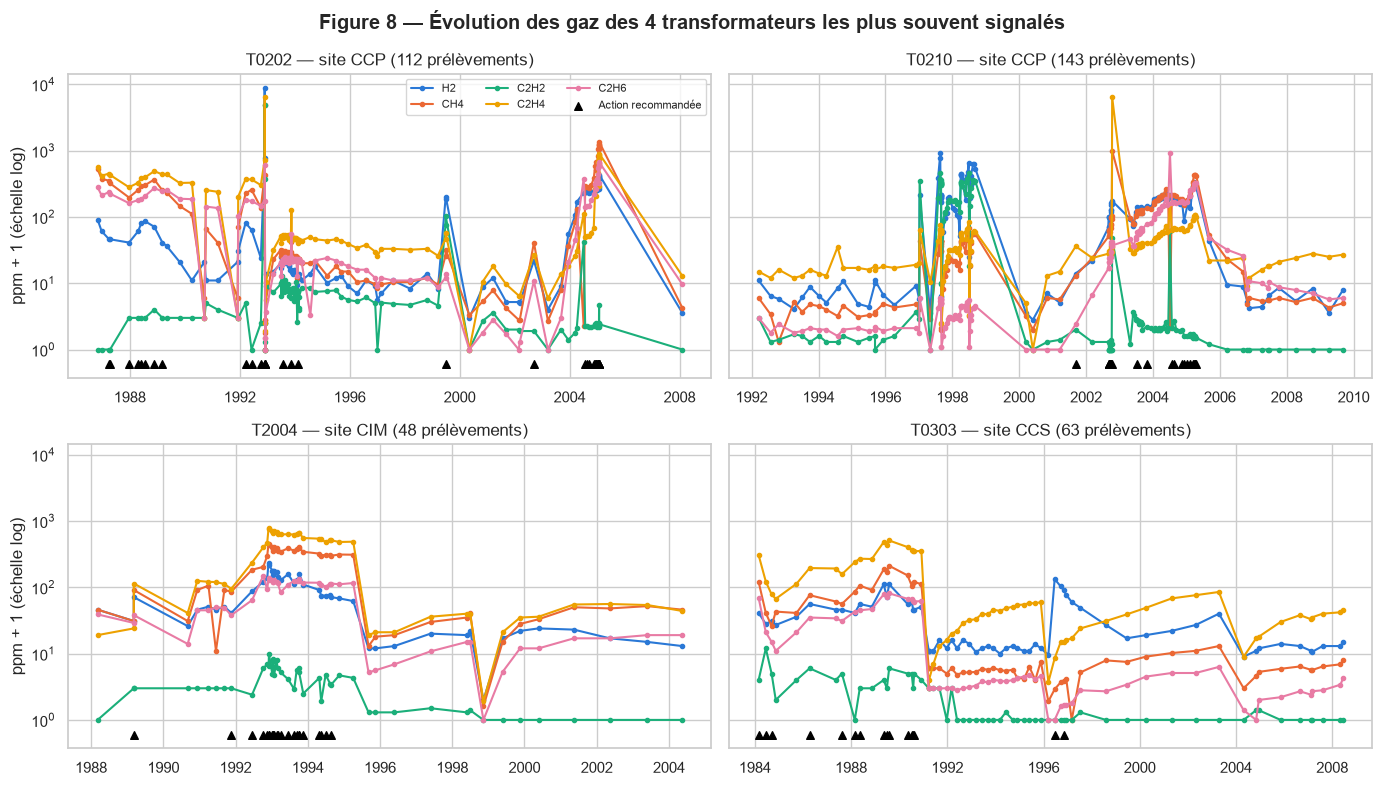

In [9]:
top4 = table.groupby("NoÉquipement")["action"].sum().nlargest(4).index
gaz_suivis = ["H2", "CH4", "C2H2", "C2H4", "C2H6"]   # gaz des défauts actifs

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, transfo in zip(axes.flat, top4):
    historique = table[table["NoÉquipement"] == transfo].sort_values("DatePrélèvement")
    for i, g in enumerate(gaz_suivis):
        ax.plot(historique["DatePrélèvement"], historique[g] + 1, marker="o", markersize=3, color=COULEURS[i], label=g)
    actions = historique[historique["action"] == 1]
    ax.scatter(actions["DatePrélèvement"], [0.6] * len(actions), marker="^", color="black", s=30, label="Action recommandée")
    ax.set_yscale("log")
    ax.set_title(f"{transfo} — site {historique['Site'].iloc[0]} ({len(historique)} prélèvements)")
axes[0, 0].set_ylabel("ppm + 1 (échelle log)")
axes[1, 0].set_ylabel("ppm + 1 (échelle log)")
axes[0, 0].legend(ncol=3, fontsize=8)
fig.suptitle("Figure 8 — Évolution des gaz des 4 transformateurs les plus souvent signalés", fontweight="bold")
plt.tight_layout()
enregistrer(fig, "fig08_evolution_gaz.png")
plt.show()

**Interprétation :** 
- Les recommandations d'action (▲) arrivent **en série, pendant les périodes où les gaz montent**. Par exemple : T0202 en 1992-1993 et en 2004-2005, T0210 en 2002-2005, T2004 en 1992-1995.
- Après ces périodes, les gaz **chutent brutalement**, d'un facteur 10 à 100 (T2004 vers 1996, T0303 vers 1991, T0202 vers 2000). Cela correspond très probablement à une **intervention** (traitement ou dégazage de l'huile, réparation), après laquelle les recommandations s'arrêtent.
- T0202 a connu un pic d'**acétylène** de plusieurs milliers de ppm fin 1992 : c'est la trace d'un **arc électrique**.

→ C'est la **tendance** qui déclenche l'action de l'expert, plus qu'une valeur isolée. C'est la limite principale de nos modèles, qui regardent un prélèvement à la fois.

### Figure 9 — Comparaison des sites
Pour chaque site : part des prélèvements dont la condition IEEE est ≥ 2 (gaz au-dessus de la normale) et part des prélèvements
avec une action recommandée.

Enregistré : rapport/figures/fig09_comparaison_sites.png


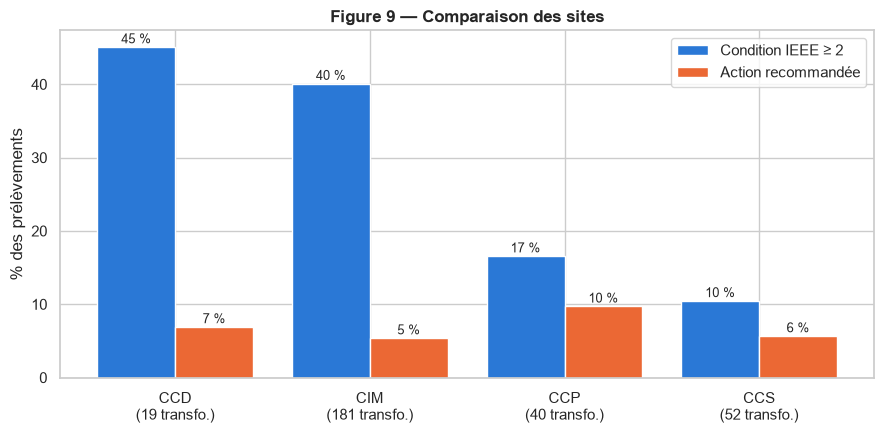

,transformateurs,prelevements,condition_2_ou_plus,action
Site,,,,
CCD,19,590,45.1,6.9
CIM,181,1868,40.1,5.4
CCP,40,1020,16.6,9.7
CCS,52,860,10.5,5.7


In [10]:
sites = table.groupby("Site").agg(
    transformateurs=("NoÉquipement", "nunique"),
    prelevements=("CléAnalyse", "count"),
    condition_2_ou_plus=("condition", lambda c: (c >= 2).mean() * 100),
    action=("action", "mean"),
)
sites["action"] = sites["action"] * 100
sites = sites.sort_values("condition_2_ou_plus", ascending=False)

x = np.arange(len(sites))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - 0.2, sites["condition_2_ou_plus"], width=0.4, color=COULEURS[0], label="Condition IEEE ≥ 2")
ax.bar(x + 0.2, sites["action"], width=0.4, color=COULEURS[1], label="Action recommandée")
for xi, (c, a) in enumerate(zip(sites["condition_2_ou_plus"], sites["action"])):
    ax.text(xi - 0.2, c + 0.5, f"{c:.0f} %", ha="center", fontsize=9)
    ax.text(xi + 0.2, a + 0.5, f"{a:.0f} %", ha="center", fontsize=9)
ax.set_xticks(x, [f"{s}\n({n} transfo.)" for s, n in zip(sites.index, sites["transformateurs"])])
ax.set_ylabel("% des prélèvements")
ax.set_title("Figure 9 — Comparaison des sites", fontweight="bold")
ax.legend()
plt.tight_layout()
enregistrer(fig, "fig09_comparaison_sites.png")
plt.show()
sites.round(1)

**Interprétation :** 
- **CCD (45 %) et CIM (40 %)** ont le plus de prélèvements au-dessus de la normale IEEE, mais **peu d'actions** (7 % et 5 %).
- **CCP** a moins de prélèvements anormaux (17 %), mais **le plus d'actions** (10 %). C'est là que se trouvent les transformateurs les plus souvent signalés (T0202, T0210) et le seul transformateur critique (T0218C).
- **Explication :** le TDCG est dominé par le **CO**, c'est-à-dire par le vieillissement du papier, fréquent à CCD et CIM. Les actions de l'expert, elles, réagissent surtout aux **défauts actifs** (H2, CH4, C2H6, C2H2), plus fréquents à CCP. On retrouve ainsi les deux familles de phénomènes vues aux étapes 2 à 4.

## 4. Interprétations finales

| N° | Constat | Preuves |
|---|---|---|
| 1 | **La majorité du parc est saine** : 78 % des transformateurs sont en condition 1 à leur dernier prélèvement | Figure 7 |
| 2 | **Deux familles de phénomènes** : le vieillissement du papier (CO, CO2 : lent et très fréquent) et les **défauts actifs** (H2, CH4, C2H6, C2H4, C2H2 : rares mais graves) | ACP (figure 2), règles d'association, figure 9 |
| 3 | **La surchauffe de l'huile est le premier déclencheur d'action** : CH4 + C2H4 élevés → action dans 62 % des cas | Figures 5 et 6 |
| 4 | **Les méthodes non supervisées retrouvent la logique de l'expert** : groupe « plus gazé » (11,5 % d'actions) et prélèvements atypiques (21 % d'actions) | Figures 3 et 4 |
| 5 | **La tendance compte plus qu'une valeur isolée** : les actions arrivent pendant les hausses de gaz, et les gaz chutent après intervention | Figure 8 |
| 6 | **Priorités** : T0218C (critique, surchauffe + arc), 4 transformateurs CIM en condition 3 (vieillissement du papier), site CCP (le plus d'actions) | Figures 7 et 9 |
| 7 | **Le suivi est irrégulier** : environ 140 transformateurs n'ont plus été analysés depuis 2000 | Figure 7 |

**Prochaine étape :** formuler les recommandations à partir de ces constats.